In [102]:
import pandas as pd
import os
import matplotlib.pyplot as plt

df_lit_fy26 = pd.read_excel(
    "Liberia_PSR_Literacy_FY26_v1.2.xlsx",
    header=2
)

df_stem_fy26 = pd.read_excel(
    "Liberia_PSR_Math&Science_FY26_v1.2.xlsx",
    header=2
)

df_health_fy26 = pd.read_excel(
    "Liberia_PSR_Community_Health_FY26_v1.1.xlsx",
    header=2
)

columns_to_fill = [
    "Objective",
    "Indicator Category",
    "Indicator"
]

df_lit_fy26[columns_to_fill] = df_lit_fy26[columns_to_fill].ffill()
df_stem_fy26[columns_to_fill] = df_stem_fy26[columns_to_fill].ffill()
df_health_fy26[columns_to_fill] = df_health_fy26[columns_to_fill].ffill()

In [104]:
df_health_fy26.head()

,Objective,Indicator Category,Indicator,Disaggregations,Unnamed: 4,Unnamed: 5,Reached,Achieved,% Achieved,FY Indicator Target,% of FY Indicator Target Met,PCVs Reporting on Indicator,Target # of PCVs Reporting on Indicator
0,Improve community health workers’ skills in a ...,Output,HE_MNCH_250_A: # individuals trained in compo...,Sex: Female,"Individual: Committees (e.g. Water, Community ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Improve community health workers’ skills in a ...,Output,HE_MNCH_250_A: # individuals trained in compo...,Sex: Female,Individual: Community Health Worker,NaN,6.0,NaN,NaN,NaN,NaN,NaN,NaN
2,Improve community health workers’ skills in a ...,Output,HE_MNCH_250_A: # individuals trained in compo...,Sex: Female,Individual: Community member,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Improve community health workers’ skills in a ...,Output,HE_MNCH_250_A: # individuals trained in compo...,Sex: Female,Individual: Family member,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Improve community health workers’ skills in a ...,Output,HE_MNCH_250_A: # individuals trained in compo...,Sex: Female,Individual: Midwife,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN


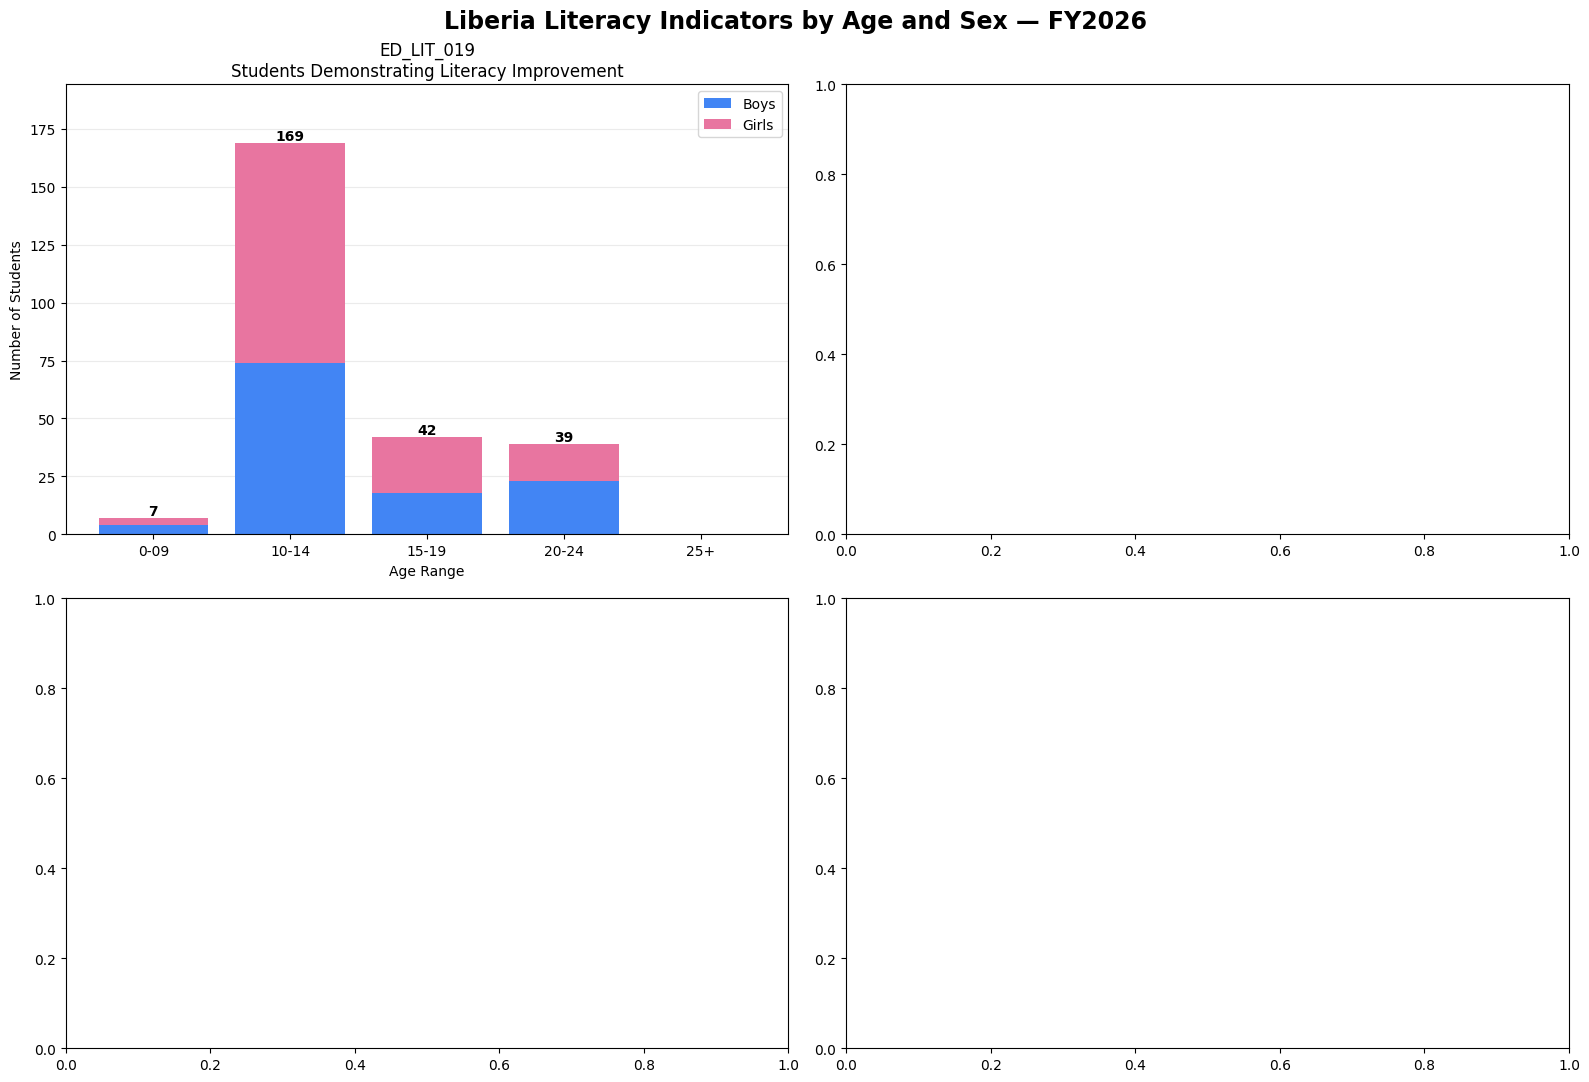

In [96]:

import pandas as pd
import matplotlib.pyplot as plt

# Choose fiscal year
df = df_lit_fy26.copy()

# Fix unnamed age column
df = df.rename(columns={"Unnamed: 4": "Age"})

# Ensure indicators are populated on every disaggregation row
df["Indicator"] = df["Indicator"].ffill()

# indicators = {
#     "ED_LIT_016": "Students Taught Literacy Skills",
#     "ED_LIT_017": "Recreational Literacy Activities",
#     "ED_LIT_018": "After-School Reading Clubs / Tutoring / Camps",
#     "ED_LIT_019": "Students Demonstrating Literacy Improvement"
# }
indicators = {"ED_LIT_019": "Students Demonstrating Literacy Improvement"}

age_order = ["0-09", "10-14", "15-19", "20-24", "25+"]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
axes = axes.flatten()

for ax, (indicator_id, title) in zip(axes, indicators.items()):

    # Filter indicator and sex disaggregations
    subset = df[
        df["Indicator"].str.startswith(indicator_id, na=False)
        & df["Disaggregations"].isin(["Sex: Male", "Sex: Female"])
    ].copy()

    # Use achieved students for literacy improvement
    metric = "Achieved" if indicator_id == "ED_LIT_019" else "Reached"

    # Extract age range
    subset["Age"] = (
        subset["Age"]
        .astype("string")
        .str.replace("Age: ", "", regex=False)
        .str.strip()
    )

    # Convert counts to numeric
    subset["Students"] = pd.to_numeric(
        subset[metric], errors="coerce"
    ).fillna(0)

    # Aggregate by age and sex
    grouped = subset.pivot_table(
        index="Age",
        columns="Disaggregations",
        values="Students",
        aggfunc="sum",
        fill_value=0
    ).reindex(
        index=age_order,
        columns=["Sex: Male", "Sex: Female"],
        fill_value=0
    )

    boys = grouped["Sex: Male"]
    girls = grouped["Sex: Female"]
    totals = boys + girls

    # Stacked bars
    ax.bar(
        age_order,
        boys,
        color="#4285F4",
        label="Boys"
    )

    ax.bar(
        age_order,
        girls,
        bottom=boys,
        color="#E875A0",
        label="Girls"
    )

    # Total labels above bars
    for i, total in enumerate(totals):
        if total > 0:
            ax.text(
                i, total,
                f"{total:,.0f}",
                ha="center",
                va="bottom",
                fontsize=10,
                fontweight="bold"
            )

    ax.set_title(f"{indicator_id}\n{title}", fontsize=12)
    ax.set_xlabel("Age Range")
    ax.set_ylabel("Number of Students")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.set_ylim(0, max(totals.max() * 1.15, 1))

fig.suptitle(
    "Liberia Literacy Indicators by Age and Sex — FY2026",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


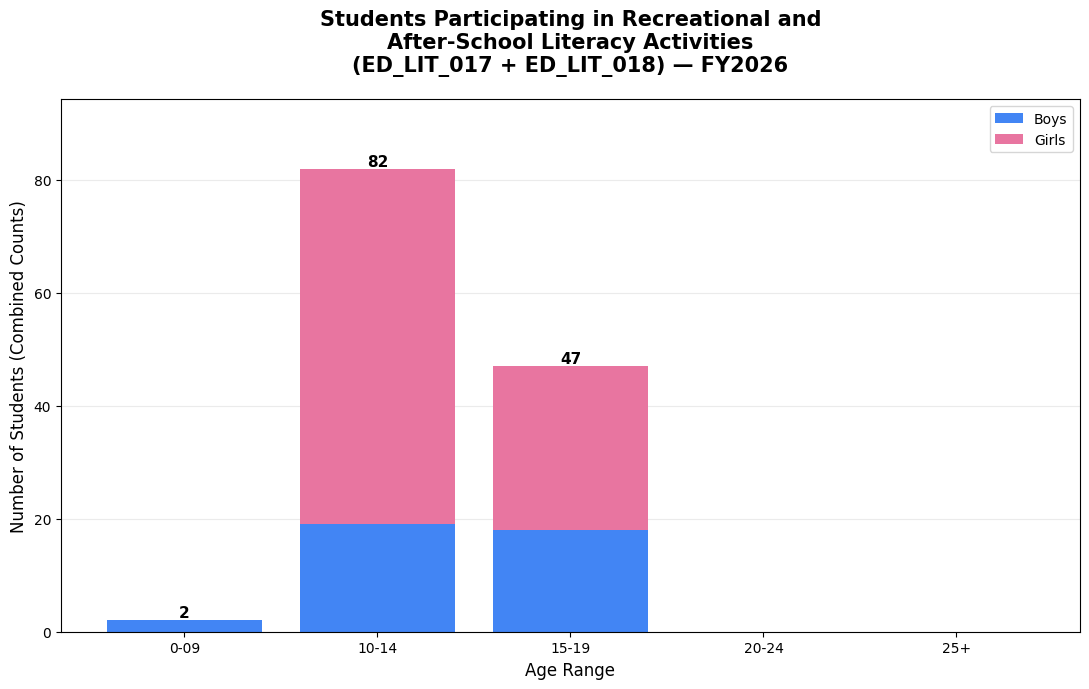

Combined reported count: 131
Boys: 39
Girls: 92


In [97]:

import pandas as pd
import matplotlib.pyplot as plt

df = df_lit_fy26.copy()

# Rename age column if needed
df = df.rename(columns={"Unnamed: 4": "Age"})

# Forward-fill indicators across disaggregation rows
df["Indicator"] = df["Indicator"].ffill()

# Select ED_LIT_017 and ED_LIT_018
subset = df[
    df["Indicator"].str.match(r"^ED_LIT_01[78]\b", na=False)
    & df["Disaggregations"].isin(["Sex: Male", "Sex: Female"])
].copy()

# Clean age ranges
subset["Age"] = (
    subset["Age"]
    .astype("string")
    .str.replace("Age: ", "", regex=False)
    .str.strip()
)

# Convert student counts to numeric
subset["Students"] = pd.to_numeric(
    subset["Reached"], errors="coerce"
).fillna(0)

age_order = ["0-09", "10-14", "15-19", "20-24", "25+"]

# Sum both indicators by age and sex
grouped = subset.pivot_table(
    index="Age",
    columns="Disaggregations",
    values="Students",
    aggfunc="sum",
    fill_value=0
).reindex(
    index=age_order,
    columns=["Sex: Male", "Sex: Female"],
    fill_value=0
)

boys = grouped["Sex: Male"]
girls = grouped["Sex: Female"]
totals = boys + girls

# Create stacked bar chart
fig, ax = plt.subplots(figsize=(11, 7))

ax.bar(
    age_order, boys,
    label="Boys",
    color="#4285F4"
)

ax.bar(
    age_order, girls,
    bottom=boys,
    label="Girls",
    color="#E875A0"
)

# Add totals above bars
for i, total in enumerate(totals):
    if total > 0:
        ax.text(
            i, total,
            f"{total:,.0f}",
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold"
        )

ax.set_title(
    "Students Participating in Recreational and\n"
    "After-School Literacy Activities\n"
    "(ED_LIT_017 + ED_LIT_018) — FY2026",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Age Range", fontsize=12)
ax.set_ylabel("Number of Students (Combined Counts)", fontsize=12)
ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.set_ylim(0, max(totals.max() * 1.15, 1))

plt.tight_layout()
plt.show()

print(f"Combined reported count: {totals.sum():,.0f}")
print(f"Boys: {boys.sum():,.0f}")
print(f"Girls: {girls.sum():,.0f}")


In [98]:

# import pandas as pd
# import matplotlib.pyplot as plt

# # --------------------------------------------------
# # Prepare ED_LIT_016 data from both fiscal years
# # --------------------------------------------------

# def prepare_indicator(df, fiscal_year):
#     data = df.copy()
#     data = data.rename(columns={"Unnamed: 4": "Age"})

#     data["Indicator"] = data["Indicator"].ffill()

#     data = data[
#         data["Indicator"].str.startswith("ED_LIT_016:", na=False)
#         & data["Disaggregations"].isin(["Sex: Male", "Sex: Female"])
#     ].copy()

#     data["Age"] = (
#         data["Age"]
#         .astype("string")
#         .str.replace("Age: ", "", regex=False)
#         .str.strip()
#     )

#     data["Students"] = pd.to_numeric(
#         data["Reached"], errors="coerce"
#     ).fillna(0)

#     data["Fiscal Year"] = fiscal_year

#     return data


# combined = pd.concat([
#     prepare_indicator(df_fy25, "FY25"),
#     prepare_indicator(df_fy26, "FY26")
# ], ignore_index=True)

# years = ["FY25", "FY26"]
# age_order = ["0-09", "10-14", "15-19", "20-24", "25+"]

# # --------------------------------------------------
# # GRAPH 1: Male vs Female over fiscal years
# # --------------------------------------------------

# sex_counts = (
#     combined.groupby(["Fiscal Year", "Disaggregations"])["Students"]
#     .sum()
#     .unstack(fill_value=0)
#     .reindex(
#         index=years,
#         columns=["Sex: Male", "Sex: Female"],
#         fill_value=0
#     )
# )

# fig, ax = plt.subplots(figsize=(10, 6))

# for sex, label, color in [
#     ("Sex: Male", "Boys", "#4285F4"),
#     ("Sex: Female", "Girls", "#E875A0")
# ]:
#     values = sex_counts[sex]

#     ax.plot(
#         years, values,
#         marker="o",
#         markersize=9,
#         linewidth=2.5,
#         label=label,
#         color=color
#     )

#     for x, y in zip(years, values):
#         ax.annotate(
#             f"{y:,.0f}",
#             (x, y),
#             xytext=(0, 10),
#             textcoords="offset points",
#             ha="center",
#             fontsize=10
#         )

# ax.set_title(
#     "ED_LIT_016: Students Taught Literacy Skills\n"
#     "by Sex — FY25 vs FY26",
#     fontsize=14,
#     fontweight="bold"
# )
# ax.set_xlabel("Fiscal Year")
# ax.set_ylabel("Number of Students")
# ax.legend()
# ax.grid(alpha=0.25)
# ax.set_ylim(bottom=0)

# plt.tight_layout()
# plt.show()


# # --------------------------------------------------
# # GRAPH 2: Age ranges over fiscal years
# # --------------------------------------------------

# age_counts = (
#     combined.groupby(["Fiscal Year", "Age"])["Students"]
#     .sum()
#     .unstack(fill_value=0)
#     .reindex(
#         index=years,
#         columns=age_order,
#         fill_value=0
#     )
# )

# fig, ax = plt.subplots(figsize=(11, 7))

# colors = [
#     "#4285F4",
#     "#E875A0",
#     "#34A853",
#     "#F9AB00",
#     "#9C6ADE"
# ]

# for age, color in zip(age_order, colors):
#     values = age_counts[age]

#     ax.plot(
#         years,
#         values,
#         marker="o",
#         markersize=9,
#         linewidth=2.5,
#         label=f"Age {age}",
#         color=color
#     )

#     # Label the FY26 value on each line
#     ax.annotate(
#         f"{values.loc['FY26']:,.0f}",
#         ("FY26", values.loc["FY26"]),
#         xytext=(8, 0),
#         textcoords="offset points",
#         va="center",
#         fontsize=10,
#         color=color
#     )

# ax.set_title(
#     "ED_LIT_016: Students Taught Literacy Skills\n"
#     "by Age Range — FY25 vs FY26",
#     fontsize=14,
#     fontweight="bold"
# )
# ax.set_xlabel("Fiscal Year")
# ax.set_ylabel("Number of Students")
# ax.legend(title="Age Range")
# ax.grid(alpha=0.25)
# ax.set_ylim(bottom=0)
# ax.margins(x=0.15)

# plt.tight_layout()
# plt.show()


In [99]:

# import numpy as np
# from matplotlib.patches import Patch
# from matplotlib.lines import Line2D
# from textwrap import shorten


# def _indicator_targets(df):
#     """Extract annual target and actual from each indicator's Total row."""
#     data = df.copy()
#     data.columns = data.columns.astype(str).str.strip()

#     fill_cols = ["Objective", "Indicator Category", "Indicator"]
#     data[fill_cols] = data[fill_cols].ffill()

#     # Avoid double-counting gender and age disaggregations.
#     totals = data[
#         data["Disaggregations"].astype(str)
#         .str.strip().str.casefold().eq("total")
#     ].copy()

#     for col in ["Reached", "Achieved", "FY Indicator Target"]:
#         totals[col] = pd.to_numeric(totals[col], errors="coerce")

#     totals["code"] = totals["Indicator"].astype(str).str.extract(
#         r"^\s*([A-Za-z]+_[A-Za-z]+_\d+)", expand=False
#     )
#     totals["code"] = totals["code"].fillna(
#         totals["Indicator"].astype(str).str.split(":").str[0].str.strip()
#     )

#     is_outcome = totals["Indicator Category"].astype(str).str.contains(
#         "outcome", case=False, na=False
#     )
#     totals["actual"] = totals["Achieved"].where(
#         is_outcome, totals["Reached"]
#     )

#     return totals.drop_duplicates("code").set_index("code")


# def plot_target_bullets(
#     df_prior, df_current, program="Literacy",
#     prior_label="FY25", current_label="FY26"
# ):
#     current = _indicator_targets(df_current)
#     prior = _indicator_targets(df_prior) if df_prior is not None else None

#     periods = (
#         ([(prior_label, prior)] if prior is not None else [])
#         + [(current_label, current)]
#     )

#     # Match indicators across years, preserving FY26 order.
#     all_codes = list(dict.fromkeys(
#         current.index.tolist()
#         + (prior.index.tolist() if prior is not None else [])
#     ))

#     # Percentage of target is undefined for zero targets.
#     codes = [
#         code for code in all_codes
#         if any(
#             code in data.index
#             and pd.notna(data.at[code, "FY Indicator Target"])
#             and data.at[code, "FY Indicator Target"] > 0
#             for _, data in periods
#         )
#     ]

#     if not codes:
#         raise ValueError("No indicators with positive annual targets found.")

#     labels = []
#     for code in codes:
#         source = current if code in current.index else prior
#         description = str(source.at[code, "Indicator"]).split(":", 1)[-1]
#         labels.append(
#             f"{code}  {shorten(description.strip(), width=48, placeholder='…')}"
#         )

#     # Use a shared horizontal scale across both years.
#     max_pct = 100.0
#     for _, data in periods:
#         for code in codes:
#             if code not in data.index:
#                 continue
#             target = data.at[code, "FY Indicator Target"]
#             actual = data.at[code, "actual"]
#             if pd.notna(target) and target > 0 and pd.notna(actual):
#                 max_pct = max(max_pct, 100 * actual / target)

#     x_max = max(135, np.ceil((max_pct + 30) / 25) * 25)

#     fig, axes = plt.subplots(
#         1, len(periods),
#         sharex=True, sharey=True,
#         figsize=(
#             17 if len(periods) == 2 else 12,
#             max(10, 0.50 * len(codes) + 2)
#         ),
#         squeeze=False
#     )
#     axes = axes[0]
#     positions = np.arange(len(codes))

#     for ax, (year, data) in zip(axes, periods):
#         for y, code in enumerate(codes):
#             if code not in data.index:
#                 ax.text(3, y, "Not included", va="center",
#                         color="0.5", fontsize=8)
#                 continue

#             row = data.loc[code]
#             target = row["FY Indicator Target"]
#             actual = row["actual"]

#             if pd.isna(target) or target <= 0:
#                 ax.text(3, y, "No positive target", va="center",
#                         color="0.5", fontsize=8)
#                 continue

#             # Background bullet bar represents 100% of target.
#             ax.barh(y, 100, height=0.62, color="0.91", zorder=1)

#             # Vertical target marker.
#             ax.vlines(
#                 100, y - 0.36, y + 0.36,
#                 color="0.15", linewidth=2, zorder=4
#             )

#             if pd.isna(actual):
#                 ax.text(3, y, "Not reported", va="center",
#                         color="0.5", fontsize=8, zorder=5)
#                 continue

#             pct = actual / target * 100
#             is_outcome = "outcome" in str(
#                 row["Indicator Category"]
#             ).casefold()

#             ax.barh(
#                 y, pct, height=0.45,
#                 color="C1" if is_outcome else "C0",
#                 zorder=2
#             )

#             ax.text(
#                 pct + 3, y,
#                 f"{actual:,.0f}/{target:,.0f} ({pct:.0f}%)",
#                 va="center", fontsize=8, zorder=5
#             )

#         ax.set(
#             title=year,
#             xlabel="Percent of annual indicator target",
#             xlim=(0, x_max)
#         )
#         ax.set_yticks(positions)
#         ax.set_yticklabels(labels, fontsize=8)
#         ax.grid(axis="x", alpha=0.17)
#         ax.set_axisbelow(True)
#         ax.tick_params(axis="y", length=0)

#     axes[0].invert_yaxis()

#     if len(axes) > 1:
#         axes[1].tick_params(labelleft=False)

#     fig.suptitle(
#         f"{program} — Results vs. Annual Targets",
#         fontsize=15, fontweight="bold"
#     )

#     fig.legend(
#         handles=[
#             Patch(facecolor="C0", label="Output: Reached"),
#             Patch(facecolor="C1", label="Outcome: Achieved"),
#             Line2D([], [], color="0.15", linewidth=2, label="100% target")
#         ],
#         loc="lower center", ncol=3, frameon=False
#     )

#     fig.tight_layout(rect=(0, 0.055, 1, 0.96))
#     plt.show()

#     excluded = [code for code in all_codes if code not in codes]
#     print(
#         f"{program}: {len(codes)} indicators with positive targets. "
#         f"Excluded {len(excluded)} indicators without positive targets."
#     )


# # LITERACY
# plot_target_bullets(df_fy25, df_fy26, program="Literacy")


In [100]:

# # STEM FY26
# df_stem_fy26 = pd.read_excel(
#     "data/projectstatusreports/Liberia_PSR_Math&Science_FY26.xlsx",
#     header=2
# )

# # FY26 targets and results
# plot_target_bullets(
#     None,
#     df_stem_fy26,
#     program="STEM",
#     current_label="FY26"
# )


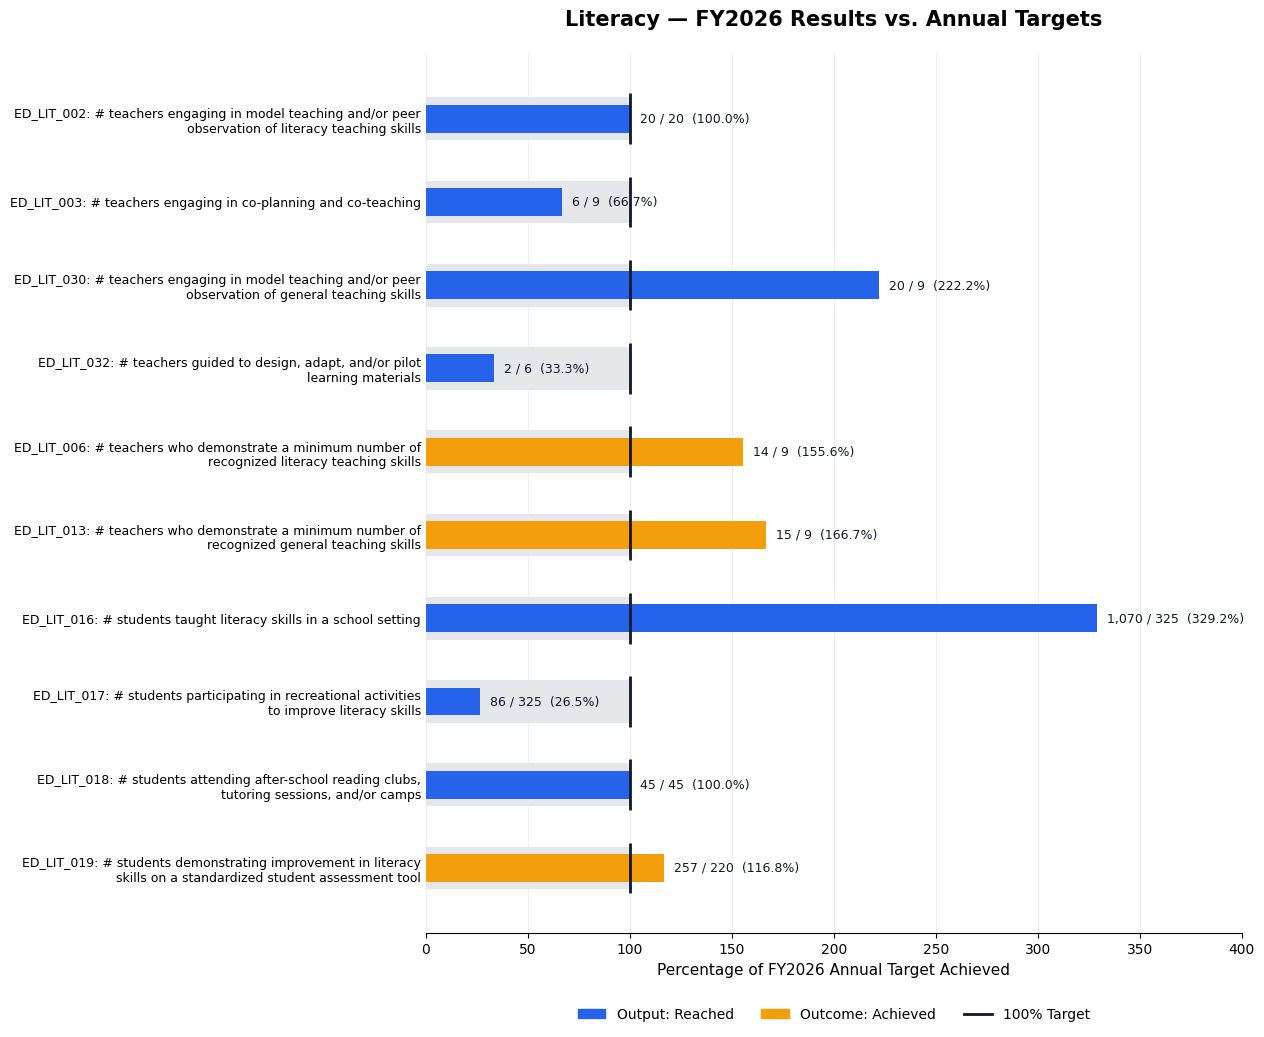

Literacy: 10 reported indicators displayed.


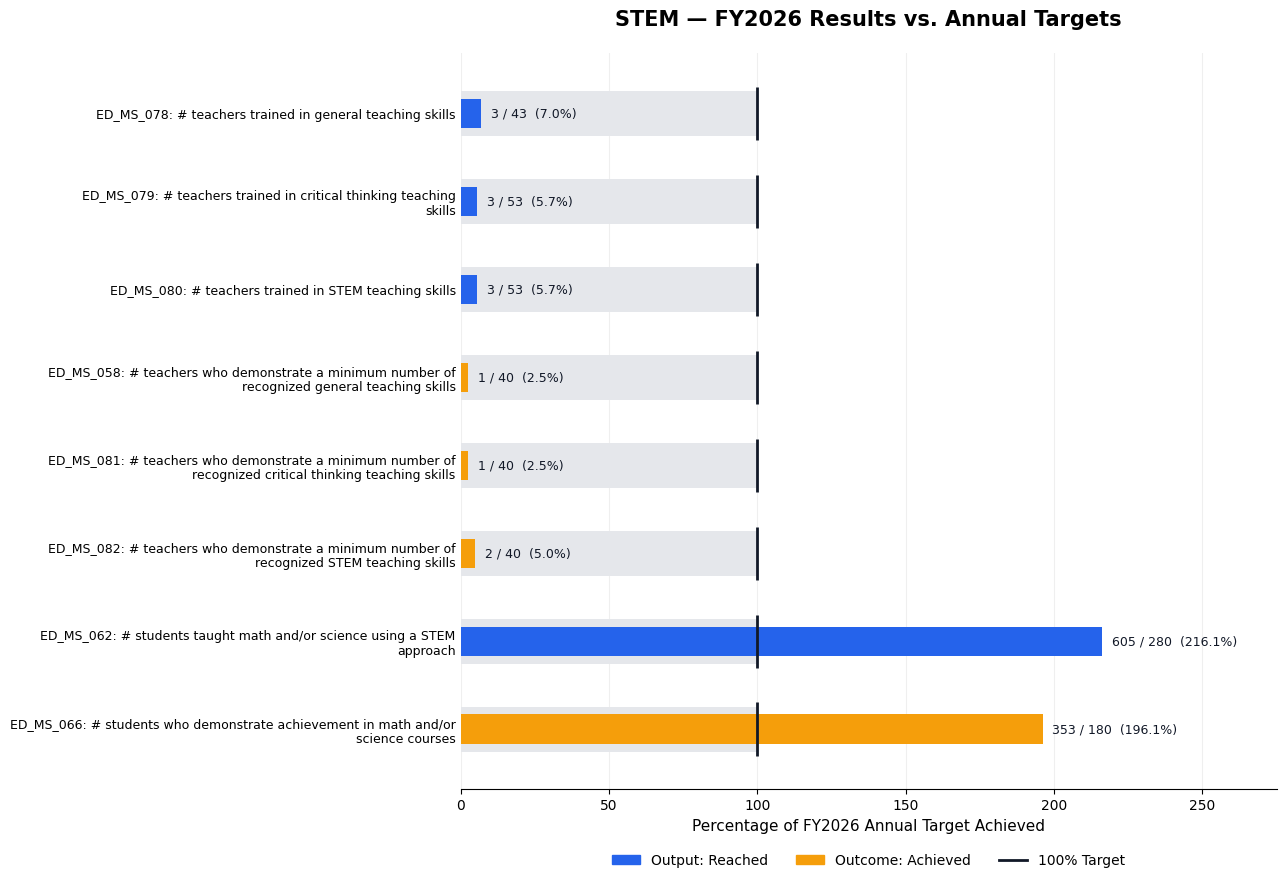

STEM: 8 reported indicators displayed.


In [101]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import textwrap
from matplotlib.patches import Patch
from matplotlib.lines import Line2D


def plot_fy26_bullets(df, program_name):
    data = df.copy()
    data.columns = data.columns.astype(str).str.strip()

    # Forward-fill merged indicator information
    cols = ["Objective", "Indicator Category", "Indicator"]
    data[cols] = data[cols].ffill()

    # Only use Total rows; exclude age/sex subcategories
    data = data[
        data["Disaggregations"]
        .astype(str)
        .str.strip()
        .str.casefold()
        .eq("total")
    ].copy()

    # Convert numeric fields
    for col in ["Reached", "Achieved", "FY Indicator Target"]:
        data[col] = pd.to_numeric(data[col], errors="coerce")

    # Use Achieved for outcomes and Reached for outputs
    data["is_outcome"] = (
        data["Indicator Category"]
        .astype(str)
        .str.contains("outcome", case=False, na=False)
    )

    data["actual"] = np.where(
        data["is_outcome"],
        data["Achieved"],
        data["Reached"]
    )

    data["target"] = data["FY Indicator Target"]

    # Remove ALL unreported metrics and invalid/zero targets
    data = data[
        data["actual"].notna()
        & data["target"].notna()
        & (data["target"] > 0)
    ].copy()

    data = data.drop_duplicates(subset=["Indicator"])

    data["percent"] = 100 * data["actual"] / data["target"]

    if data.empty:
        print(f"No reported indicators for {program_name}.")
        return

    # Keep complete indicator titles, wrapping instead of truncating
    labels = [
        textwrap.fill(
            str(title),
            width=65,
            break_long_words=False,
            break_on_hyphens=False
        )
        for title in data["Indicator"]
    ]

    n = len(data)
    positions = np.arange(n) * 1.25

    fig, ax = plt.subplots(
        figsize=(17, max(6, n * 0.90 + 2))
    )

    # Allow bars above 100% and room for numeric annotations
    max_percent = max(100, data["percent"].max())
    x_max = max(140, np.ceil(max_percent * 1.20 / 25) * 25)

    for y, (_, row) in zip(positions, data.iterrows()):
        pct = row["percent"]
        actual = row["actual"]
        target = row["target"]

        # Gray reference bar up to 100% target
        ax.barh(
            y, 100,
            height=0.64,
            color="#E5E7EB",
            zorder=1
        )

        # Actual results
        color = "#F59E0B" if row["is_outcome"] else "#2563EB"

        ax.barh(
            y, pct,
            height=0.42,
            color=color,
            zorder=2
        )

        # Target marker at 100%
        ax.vlines(
            100,
            y - 0.38,
            y + 0.38,
            color="#111827",
            linewidth=2,
            zorder=3
        )

        # Actual, target, and target attainment
        ax.text(
            pct + max(3, x_max * 0.012),
            y,
            f"{actual:,.0f} / {target:,.0f}  ({pct:.1f}%)",
            va="center",
            fontsize=9,
            color="#111827"
        )

    ax.set_yticks(positions)
    ax.set_yticklabels(labels, fontsize=9)
    ax.invert_yaxis()

    ax.set_xlim(0, x_max)
    ax.set_xlabel(
        "Percentage of FY2026 Annual Target Achieved",
        fontsize=11
    )

    ax.set_title(
        f"{program_name} — FY2026 Results vs. Annual Targets",
        fontsize=15,
        fontweight="bold",
        pad=20
    )

    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.legend(
        handles=[
            Patch(color="#2563EB", label="Output: Reached"),
            Patch(color="#F59E0B", label="Outcome: Achieved"),
            Line2D(
                [0], [0],
                color="#111827",
                linewidth=2,
                label="100% Target"
            )
        ],
        loc="upper center",
        bbox_to_anchor=(0.5, -0.07),
        ncol=3,
        frameon=False
    )

    # Wide left margin accommodates full metric names
    fig.subplots_adjust(
        left=0.46,
        right=0.94,
        top=0.92,
        bottom=0.12
    )

    plt.show()

    print(f"{program_name}: {n} reported indicators displayed.")



plot_fy26_bullets(df_lit_fy26, "Literacy")


plot_fy26_bullets(df_stem_fy26, "STEM")
